# Flower Recognition

Real flower photos from the TensorFlow `flower_photos` set (3,670 Flickr photos in 5 classes, CC BY 2.0), downloaded straight from TensorFlow's public storage bucket. I first looked at `torchvision.datasets.Flowers102`, but 102 classes with a few dozen images each is too thin for a from-scratch CNN on CPU, while the 5-class set is a good fit.

To keep training on CPU short I take 150 photos per class (750 total), resize them to 96x96, and train the small CNN for 4 epochs.

In [1]:
import io, tarfile, urllib.request
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

torch.set_num_threads(2)
np.random.seed(8); torch.manual_seed(8)

In [2]:
FLOWER_CLASSES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
SIZE = 96
PER_CLASS = 150

DATA = Path("../../data/flowers")
TGZ = DATA / "flower_photos.tgz"
if not TGZ.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", TGZ)

# collect file names per class, then take a random PER_CLASS of each
with tarfile.open(TGZ) as tf:
    members = [m for m in tf.getmembers() if m.isfile() and m.name.endswith(".jpg")]
    rng = np.random.default_rng(8)
    chosen = []
    for c, name in enumerate(FLOWER_CLASSES):
        cls = [m for m in members if m.name.split("/")[1] == name]
        chosen += [(m, c) for m in rng.choice(cls, PER_CLASS, replace=False)]
    X = np.zeros((len(chosen), SIZE, SIZE, 3), dtype=np.float32)
    y = np.zeros(len(chosen), dtype=np.int64)
    for i, (m, c) in enumerate(chosen):
        im = Image.open(io.BytesIO(tf.extractfile(m).read())).convert("RGB").resize((SIZE, SIZE))
        X[i] = np.asarray(im, dtype=np.float32) / 255.0
        y[i] = c
print('real flower photos:', X.shape, '| per class:', np.bincount(y))

real flower photos: (750, 96, 96, 3) | per class: [150 150 150 150 150]


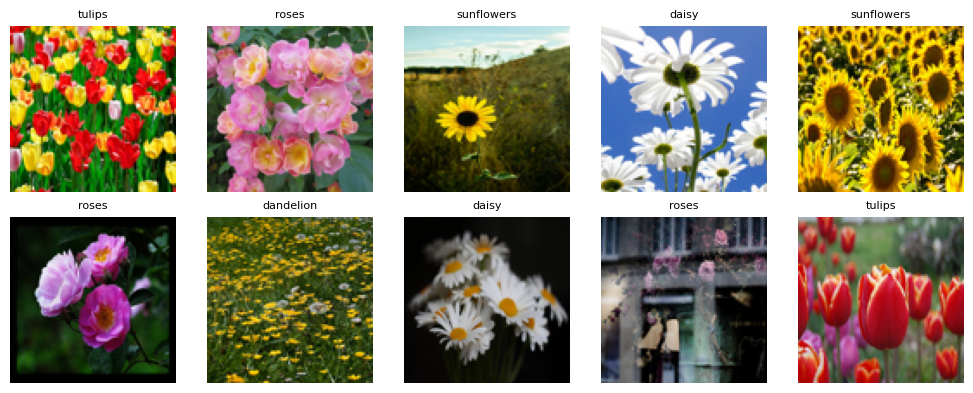

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, np.random.choice(len(X), 10, replace=False)):
    ax.imshow(X[idx]); ax.set_title(FLOWER_CLASSES[y[idx]], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
Xt = torch.tensor(X).permute(0, 3, 1, 2)  # (N,3,H,W)
yt = torch.tensor(y)
Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=8)
Xtr = torch.tensor(Xtr); Xte = torch.tensor(Xte); ytr = torch.tensor(ytr); yte = torch.tensor(yte)
print('train', Xtr.shape, '| test', Xte.shape)

train torch.Size([600, 3, 96, 96]) | test torch.Size([150, 3, 96, 96])


In [5]:
class FlowerCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv2d(3, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.c3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Linear(64, n_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = self.pool(F.relu(self.c3(x)))
        x = self.gap(x).flatten(1)
        return self.fc(x)

model = FlowerCNN(len(FLOWER_CLASSES))
opt = torch.optim.Adam(model.parameters(), lr=2e-3)

batch = 32
for ep in range(4):
    model.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = model(Xtr[idx])
        loss = F.cross_entropy(out, ytr[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=1.5914


epoch 1  mean_loss=1.4705


epoch 2  mean_loss=1.4010


epoch 3  mean_loss=1.2942


In [6]:
model.eval()
with torch.no_grad():
    preds = model(Xte).argmax(1).numpy()
print(classification_report(yte.numpy(), preds, target_names=FLOWER_CLASSES, zero_division=0))

              precision    recall  f1-score   support

       daisy       0.45      0.47      0.46        30
   dandelion       0.41      0.30      0.35        30
       roses       0.67      0.33      0.44        30
  sunflowers       0.48      0.93      0.64        30
      tulips       0.46      0.37      0.41        30

    accuracy                           0.48       150
   macro avg       0.49      0.48      0.46       150
weighted avg       0.49      0.48      0.46       150



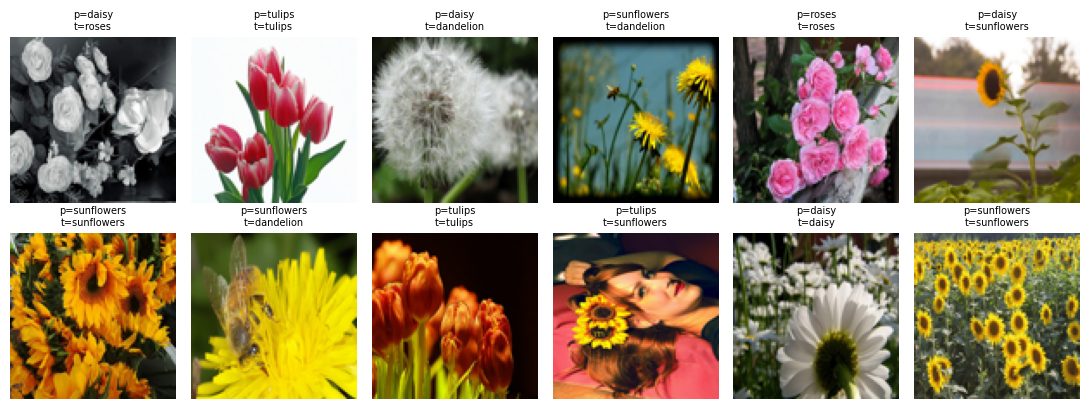

In [7]:
# show some predictions
fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
show = np.random.choice(len(Xte), 12, replace=False)
with torch.no_grad():
    p = model(Xte[show]).argmax(1).numpy()
for ax, i, pi in zip(axes.flat, show, p):
    img = Xte[i].permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(f'p={FLOWER_CLASSES[pi]}\nt={FLOWER_CLASSES[yte[i].item()]}', fontsize=7)
    ax.axis('off')
plt.tight_layout(); plt.show()

## Takeaways

On 150 held-out real photos the small from-scratch CNN gets 48% accuracy after 4 epochs on 600 training images, against 20% for random guessing. The loss was still falling (1.59 to 1.29), so it's undertrained rather than stuck. Sunflowers are the easy class (recall 0.93), helped by their strong yellow-and-brown color. Roses, tulips and dandelions get mixed up the most, which makes sense: roses and tulips come in many colors, and a 96x96 photo of a dandelion often looks like a yellow blob in grass.

This is the honest baseline for a tiny CNN on CPU. It shows why transfer learning is basically required for real photos with only a few hundred examples per class. The obvious next step is the same pattern as notebook 59: a frozen ImageNet ResNet18 backbone with only a linear head trained on top. More epochs, the full 3,670 photos and flip / crop augmentation would also help the from-scratch model.